<a href="https://colab.research.google.com/github/mishraaashkacs242511-maker/Machine-Learning-Fundamentals/blob/main/ML_Fundamentals_Prac_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. KNN for botanical species identification
Implement KNN (Euclidean distance, experiment with K=3,5,7) on the Iris
dataset to classify flower species (real-world agriculture/plant taxonomy).
Compute distance manually for first 5 test samples.

Graph 1: Before implementing KNN

First 5 rows of Iris Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


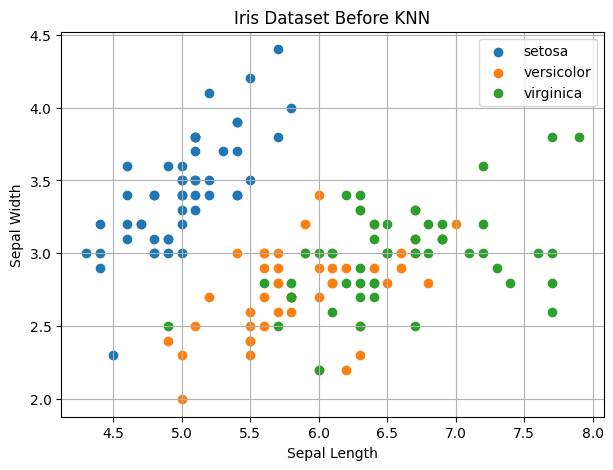

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['Species'] = iris.target_names[y]

print("First 5 rows of Iris Dataset:")
print(df.head())

plt.figure(figsize=(7, 5))

for i, species in enumerate(iris.target_names):
    plt.scatter(
        X[y == i, 0],
        X[y == i, 1],
        label=species
    )

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Iris Dataset Before KNN")
plt.legend()
plt.grid()
plt.show()

Graph 2: Euclidean distances of first test sample


Test Sample: 1
Actual Species: setosa
Nearest Distances: [0.14142136 0.24494897 0.3        0.3        0.36055513]
Nearest Species: ['setosa' 'setosa' 'setosa' 'setosa' 'setosa']

Test Sample: 2
Actual Species: virginica
Nearest Distances: [0.24494897 0.28284271 0.3        0.36055513 0.42426407]
Nearest Species: ['virginica' 'virginica' 'versicolor' 'virginica' 'versicolor']

Test Sample: 3
Actual Species: versicolor
Nearest Distances: [0.38729833 0.45825757 0.72111026 0.78740079 0.83666003]
Nearest Species: ['versicolor' 'versicolor' 'versicolor' 'versicolor' 'versicolor']

Test Sample: 4
Actual Species: versicolor
Nearest Distances: [0.36055513 0.38729833 0.64807407 0.72111026 0.78740079]
Nearest Species: ['versicolor' 'versicolor' 'versicolor' 'versicolor' 'versicolor']

Test Sample: 5
Actual Species: setosa
Nearest Distances: [0.2236068  0.3        0.3        0.31622777 0.31622777]
Nearest Species: ['setosa' 'setosa' 'setosa' 'setosa' 'setosa']


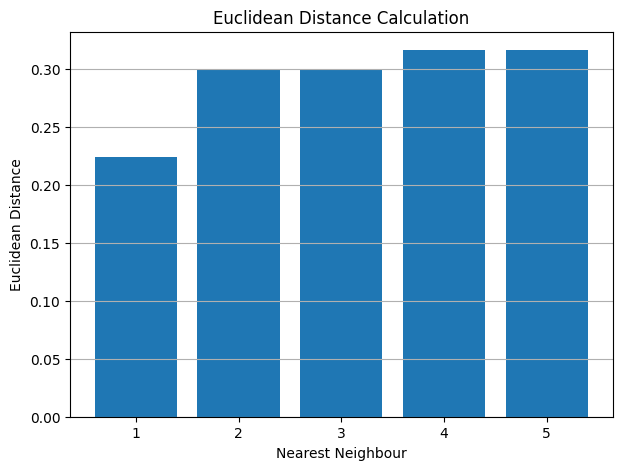

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

for i in range(5):
    distances = []

    for j in range(len(X_train)):
        d = euclidean_distance(X_test[i], X_train[j])
        distances.append(d)

    distances = np.array(distances)

    nearest = np.argsort(distances)[:5]

    print("\nTest Sample:", i + 1)
    print("Actual Species:", iris.target_names[y_test[i]])
    print("Nearest Distances:", distances[nearest])
    print("Nearest Species:", iris.target_names[y_train[nearest]])

plt.figure(figsize=(7, 5))

plt.bar(range(1, 6), distances[nearest])

plt.xlabel("Nearest Neighbour")
plt.ylabel("Euclidean Distance")
plt.title("Euclidean Distance Calculation")
plt.xticks(range(1, 6))
plt.grid(axis='y')
plt.show()

Graph 3: After implementing KNN


K = 3
Accuracy: 100.0 %

K = 5
Accuracy: 100.0 %

K = 7
Accuracy: 96.67 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



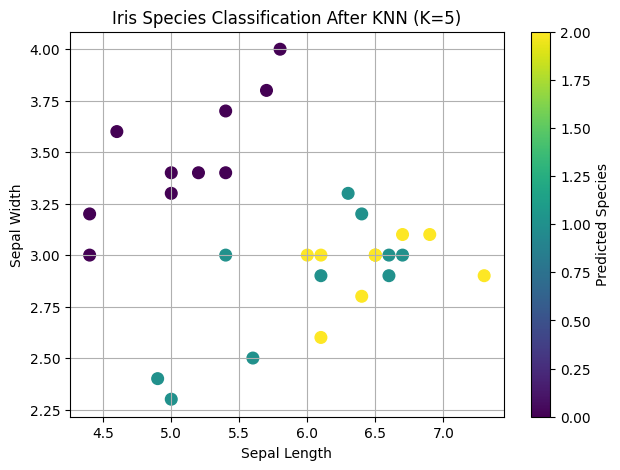

In [ ]:
k_values = [3, 5, 7]

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    print("\nK =", k)
    print("Accuracy:", round(accuracy * 100, 2), "%")

model = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            target_names=iris.target_names))

plt.figure(figsize=(7, 5))

plt.scatter(
    X_test[:, 0], X_test[:, 1],
    c=y_pred, cmap='viridis',
    marker='o', s=70, label='Predicted'
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Iris Species Classification After KNN (K=5)")
plt.grid()
plt.colorbar(label="Predicted Species")
plt.show()